# Guided SQL Series & Exploratory Analysis with SQL

## Part 1: Guided SQL Series — Querying a Customer Database

### Step 1: Connect to Data

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('data.sqlite')

> **Data note:** In this database the numeric columns (`creditLimit`, `amount`, `quantityOrdered`) are stored as **TEXT**. SQLite sorts any text value as greater than any number, so a plain `creditLimit > 25000` wrongly lets everything through. Wherever I compare or sort on one of these columns I wrap it in `CAST(... AS REAL)`. (`SUM` and `AVG` convert automatically.)

### Step 2: Limited Edition California Product

In [2]:
q2 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName,
       city, state, CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY CAST(creditLimit AS REAL) DESC;
"""
df_ca_customers = pd.read_sql(q2, conn)
df_ca_customers

,customerNumber,customerName,contactFirstName,contactLastName,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

In [3]:
q3 = """
SELECT customerNumber, customerName, contactFirstName, contactLastName, city, country
FROM customers
WHERE customerName LIKE '%Collect%'
  AND country <> 'USA'
ORDER BY country, customerName;
"""
df_collectable = pd.read_sql(q3, conn)
df_collectable

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
1,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
7,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


**Reflection – the WHERE clause, explained for a non-technical manager**

The `WHERE` clause is a filter with two conditions that must *both* be true (that is what `AND` means) for a customer to appear:

1. `customerName LIKE '%Collect%'` — keep only customers whose name contains the text "Collect". The `%` signs are wildcards meaning "anything can come before or after", so it catches *Collectors*, *Collectables*, and *Collections*. (SQLite's `LIKE` ignores upper/lower case, so a name written "collect" would be caught too.)
2. `country <> 'USA'` — `<>` means "is not equal to", so any US customer is removed, leaving only international ones.

Because both must hold, a US customer named "Collectable Mini Designs" fails the second test and is excluded, and an international customer called "Euro+ Shopping Channel" fails the first. What remains is exactly the international customers with "Collect" in their name.

### Step 4: USA Credit and Inventory Policy — Visual Required

In [4]:
q4 = """
SELECT state,
       ROUND(AVG(creditLimit), 2) AS avg_credit_limit,
       COUNT(*)                   AS num_customers
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
df_state_credit = pd.read_sql(q4, conn)
df_state_credit

,state,avg_credit_limit,num_customers
0,NH,114200.00,1
1,NY,89966.67,6
2,PA,84766.67,3
3,CA,83854.55,11
4,NV,71800.00,1
5,MA,70755.56,9
6,CT,57350.00,4
7,NJ,43000.00,1


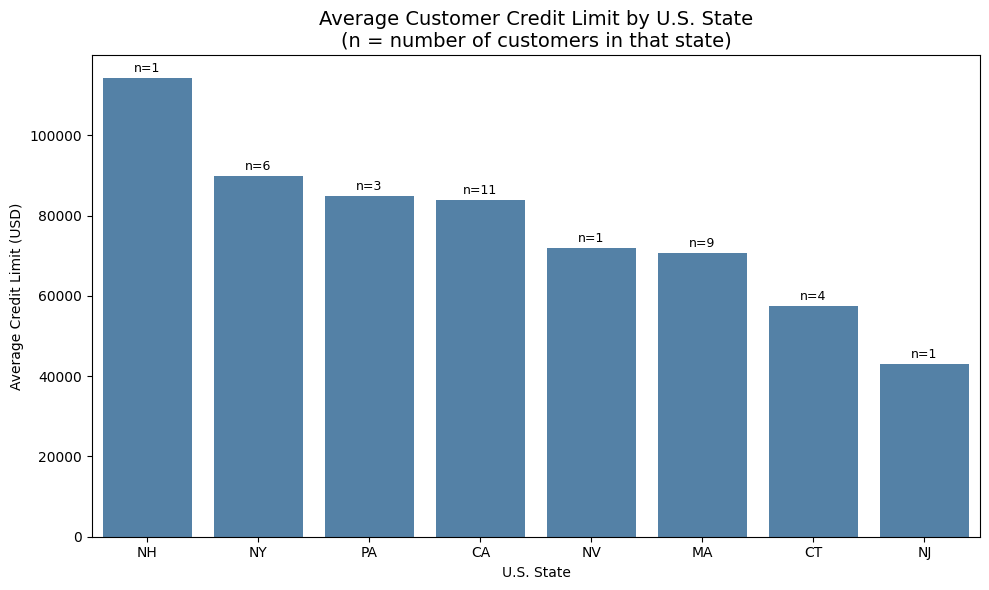

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_state_credit, x='state', y='avg_credit_limit', color='steelblue', ax=ax)
for i, row in df_state_credit.iterrows():
    ax.text(i, row.avg_credit_limit + 1500, f"n={row.num_customers}", ha='center', fontsize=9)
ax.set_title('Average Customer Credit Limit by U.S. State\n(n = number of customers in that state)', fontsize=14)
ax.set_xlabel('U.S. State')
ax.set_ylabel('Average Credit Limit (USD)')
plt.tight_layout()
plt.show()

*Caution for the product team:* NH and NV (and NJ) each have a single customer, so their averages reflect one account, not a state-wide pattern. NY, PA, CA and MA have enough customers to be more meaningful.

### Step 5: Top Customers — Visual Required

In [6]:
q5 = """
SELECT c.customerName,
       ROUND(SUM(p.amount), 2) AS total_payments
FROM customers c
JOIN payments p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
df_top_customers = pd.read_sql(q5, conn)
df_top_customers

,customerName,total_payments
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


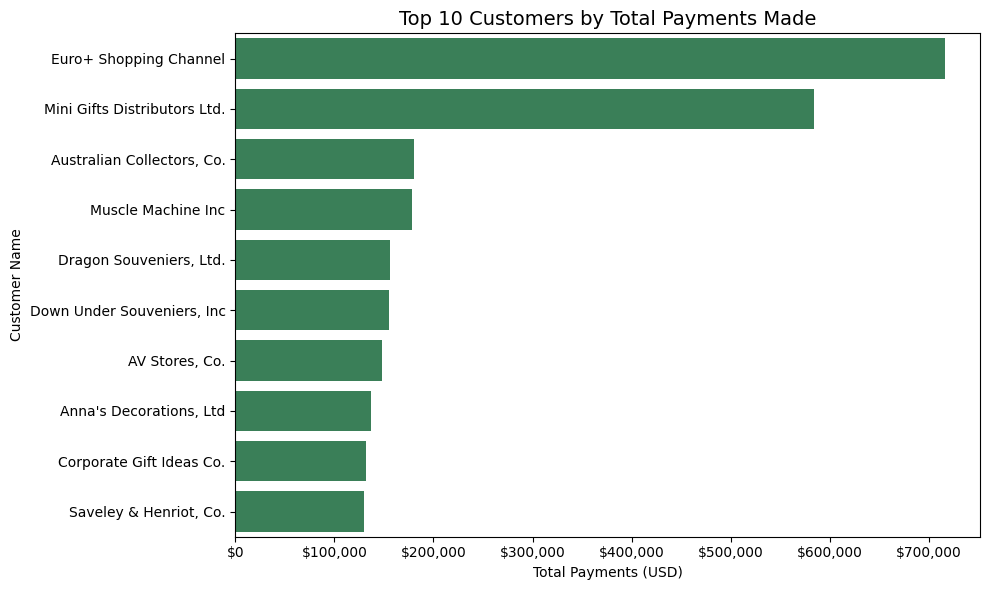

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_top_customers, y='customerName', x='total_payments', color='seagreen', ax=ax)
ax.set_title('Top 10 Customers by Total Payments Made', fontsize=14)
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')
ax.xaxis.set_major_formatter(lambda x, _: f"${x:,.0f}")
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities

In [8]:
q6 = """
SELECT c.customerNumber, c.customerName, p.productName,
       SUM(od.quantityOrdered) AS total_quantity
FROM customers c
JOIN orders o        ON c.customerNumber = o.customerNumber
JOIN orderdetails od ON o.orderNumber    = od.orderNumber
JOIN products p      ON od.productCode   = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_quantity ASC;
"""
df_customer_products = pd.read_sql(q6, conn)
df_customer_products

,customerNumber,customerName,productName,total_quantity
0,314,Petit Auto,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,1969 Chevrolet Camaro Z28,13
...,...,...,...,...
2526,141,Euro+ Shopping Channel,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,1958 Chevy Corvette Limited Edition,245


`GROUP BY` collapses rows to one per customer-product pair, `HAVING` then filters those groups (it must come after `GROUP BY` because it filters on the aggregated total, which `WHERE` cannot see), and `ORDER BY` sorts the surviving groups last.

### Step 7: Product Analysis — Visual Required

In [9]:
q7 = """
SELECT p.productLine,
       COUNT(DISTINCT p.productCode)  AS number_of_products,
       SUM(od.quantityOrdered)        AS total_quantity_ordered
FROM products p
JOIN orderdetails od ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
"""
df_product_lines = pd.read_sql(q7, conn)
df_product_lines

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


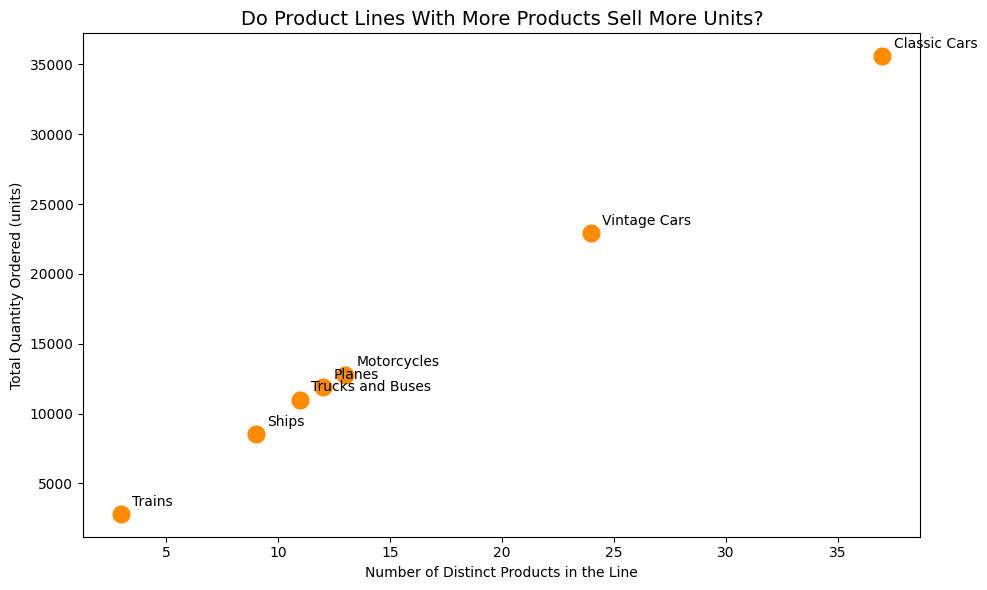

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df_product_lines, x='number_of_products', y='total_quantity_ordered',
                s=200, color='darkorange', ax=ax)
for _, r in df_product_lines.iterrows():
    ax.annotate(r.productLine, (r.number_of_products, r.total_quantity_ordered),
                textcoords='offset points', xytext=(8, 6))
ax.set_title('Do Product Lines With More Products Sell More Units?', fontsize=14)
ax.set_xlabel('Number of Distinct Products in the Line')
ax.set_ylabel('Total Quantity Ordered (units)')
plt.tight_layout()
plt.show()

**Reflection – choice of visual**

I used a **scatter plot** because the question is about the *relationship between two numbers*: how many products a line offers, and how many units customers ordered. Each dot is one product line, placed according to those two numbers, so you can see at a glance whether dots climb as you move right. A bar chart would show each number separately and make you compare two charts in your head.

The dots form a nearly straight upward line: lines with more products (Classic Cars with 37, Vintage Cars with 24) also sell far more units, while small lines (Trains with 3) sell the least. So, in this data, a bigger range goes hand in hand with more orders. A scatter plot only shows association, though; it can't tell us whether the extra products *cause* the extra sales, or whether popular lines simply get expanded. With only 7 lines, it is a preliminary indication.

### Step 8: Remote Offices

In [11]:
q8 = """
SELECT e.employeeNumber, e.firstName, e.lastName, e.jobTitle,
       e.officeCode, o.city AS office_city, o.country AS office_country,
       m.firstName || ' ' || m.lastName AS supervisor,
       m.jobTitle AS supervisor_title
FROM employees e
JOIN offices o        ON e.officeCode   = o.officeCode
LEFT JOIN employees m ON e.reportsTo    = m.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY e.officeCode, e.lastName;
"""
df_remote = pd.read_sql(q8, conn)
df_remote

,employeeNumber,firstName,lastName,jobTitle,officeCode,office_city,office_country,supervisor,supervisor_title
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,NYC,USA,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,5,Tokyo,Japan,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,5,Tokyo,Japan,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,Mary Patterson,VP Sales


**Reflection – the subquery**

The question has two layers: first *which offices* have fewer than 5 employees, and only then *who works there*. The first layer needs counting per office, which is an aggregate (`GROUP BY officeCode` + `HAVING COUNT(*) < 5`). The aggregation can only return office-level rows, but management wants employee-level rows with job title and supervisor, so I put the counting in a **subquery** that returns just a list of office codes. The outer query then keeps only employees whose `officeCode` is `IN` that list, and joins to `offices` (for location) and back to `employees` as `m` (a self-join on `reportsTo`) to get each person's supervisor. A `LEFT JOIN` keeps anyone without a supervisor from being dropped.

### Step 9: Close the Connection

In [12]:
conn.close()

---
## Part 2: Exploratory Analysis with SQL (IMDB movies)

In [16]:
import zipfile

with zipfile.ZipFile('im.db.zip', 'r') as zip_ref:
    zip_ref.extractall('./')

conn4 = sqlite3.connect('im.db')

schema_df = pd.read_sql("SELECT name, sql FROM sqlite_master WHERE type='table'", conn4)
schema_df

,name,sql
0,movie_basics,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,directors,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,known_for,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,movie_akas,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,movie_ratings,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,persons,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,principals,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,writers,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


### Initial exploration: size, years, and missing values

In [17]:
df_counts = pd.read_sql("""
SELECT 'movie_basics' AS tbl, COUNT(*) AS n FROM movie_basics
UNION ALL SELECT 'movie_ratings', COUNT(*) FROM movie_ratings
UNION ALL SELECT 'movie_akas', COUNT(*) FROM movie_akas
UNION ALL SELECT 'persons', COUNT(*) FROM persons
UNION ALL SELECT 'principals', COUNT(*) FROM principals
""", conn4)
df_counts

,tbl,n
0,movie_basics,146144
1,movie_ratings,73856
2,movie_akas,331703
3,persons,606648
4,principals,1028186


In [18]:
df_years = pd.read_sql("""
SELECT start_year, COUNT(*) AS n_movies FROM movie_basics
GROUP BY start_year ORDER BY start_year
""", conn4)
df_years

,start_year,n_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [19]:
df_nulls = pd.read_sql("""
SELECT COUNT(*)                          AS total_movies,
       SUM(runtime_minutes IS NULL)      AS null_runtime,
       SUM(genres IS NULL)               AS null_genres,
       SUM(start_year > 2019)            AS after_2019
FROM movie_basics
""", conn4)
df_nulls

,total_movies,null_runtime,null_genres,after_2019
0,146144,31739,5408,1063


### Genres: quality vs. audience engagement
Filters: release year ≤ 2019, and no null genres, runtime or ratings. Genres are comma-separated lists, so I explode them in Pandas (one row per movie-genre).

In [20]:
df_movies = pd.read_sql("""
SELECT mb.movie_id, mb.genres, mb.runtime_minutes, mb.start_year,
       r.averagerating, r.numvotes
FROM movie_basics mb
JOIN movie_ratings r ON mb.movie_id = r.movie_id
WHERE mb.start_year <= 2019
  AND mb.genres IS NOT NULL
  AND mb.runtime_minutes IS NOT NULL
""", conn4)

df_genre = df_movies.assign(genre=df_movies.genres.str.split(',')).explode('genre')
genre_summary = (df_genre.groupby('genre')
                 .agg(n_movies=('movie_id', 'count'),
                      avg_rating=('averagerating', 'mean'),
                      median_votes=('numvotes', 'median'))
                 .query('n_movies >= 1000')
                 .sort_values('avg_rating', ascending=False)
                 .round(2).reset_index())
genre_summary

,genre,n_movies,avg_rating,median_votes
0,Documentary,16423,7.32,21.0
1,Biography,3693,7.17,41.0
2,Music,1844,7.07,45.0
3,History,2704,7.05,40.0
4,Sport,1099,6.96,70.0
5,Family,3231,6.40,56.0
6,Drama,28394,6.39,85.0
7,Animation,1615,6.25,121.0
8,Adventure,3621,6.18,131.0
9,Romance,5976,6.15,149.0


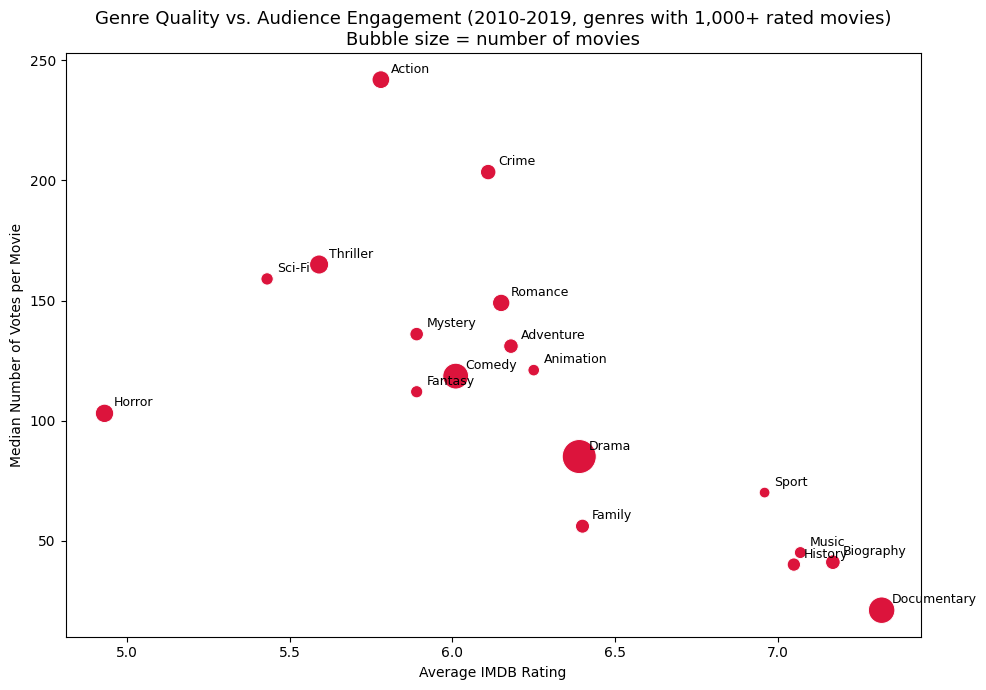

In [21]:
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=genre_summary, x='avg_rating', y='median_votes', size='n_movies',
                sizes=(60, 600), legend=False, color='crimson', ax=ax)
for _, r in genre_summary.iterrows():
    ax.annotate(r.genre, (r.avg_rating, r.median_votes), textcoords='offset points', xytext=(7, 5), fontsize=9)
ax.set_title('Genre Quality vs. Audience Engagement (2010-2019, genres with 1,000+ rated movies)\nBubble size = number of movies', fontsize=13)
ax.set_xlabel('Average IMDB Rating')
ax.set_ylabel('Median Number of Votes per Movie')
plt.tight_layout()
plt.show()

### Findings
- 146,144 titles in `movie_basics`, but only 73,856 (about half) have a rating; of those with ratings, ~65,700 also have genre and runtime.
- Drama (28k), Documentary (16k) and Comedy (15k) are the largest genres among rated movies.
- **Quality and engagement point in opposite directions.** Documentary, Biography and History have the highest average ratings (7.2-7.3) but the lowest median votes (about 20-40); Action, Thriller and Crime have middling ratings (5.6-6.1) but the highest median votes (about 165-240).
- Horror (4.9) and Sci-Fi (5.4) are the lowest rated genres.

### Business question
**For a studio choosing which genres to fund, which genres combine above-average audience ratings with above-average audience engagement (votes), and does runtime change that picture?**

### Data-cleaning tasks identified
1. Drop or flag titles with `start_year` > 2019 (including an obvious typo of 2115).
2. Exclude nulls: runtime missing for ~31.7k movies, genres for ~5.4k, and ratings missing for half the titles; `persons.birth_year` is mostly null.
3. Split the comma-separated `genres` column into one row per genre (normalise).
4. Treat runtime outliers (max is 51,420 min; 290 films under 40 min, 43 over 300 min).
5. Low-vote ratings are unreliable (median 62 votes; some movies have 5); set a minimum vote threshold.
6. Deduplicate: ~1,870 title/year pairs appear more than once in `movie_basics`; `movie_akas.region` is null for 53k rows; standardise region/language codes.
7. Check `primary_title` vs `original_title` mismatches (14k) and inconsistent title text.